# **FV Solver for the coupled Richards' and heat transport equation**
## Parametrization: Capillary Bundle Model

Author: Anne Hermann   \
anne.hermann@uni-tuebingen.de

In [ ]:
import sys
sys.path.append('../../')
import jax.numpy as jnp
from utils.geometry import Geom
import utils.petrophysic as petro
import utils.petrophysics_capillaryBundles as petro_cap
from utils import plotting_utils

### Mesh Generation

In [2]:
dz = 0.025       # grid spacing [m]
dx = 0.025    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10   # length of the domain [m]
slope = -0.1   # slope of the domain [-]

geom = Geom(dx, dz, 0, xtot, -ztot, 0, slope)  # geometry object
geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  400 x 40 cells.


In [3]:
geom.set_sparsity_pattern_coupled()

===============   Calculating coupled sparsity pattern   =============== 
DONE: calculated coupled sparsity pattern with 316480 nonzero entries.


### Time Discretization

In [4]:
dt = 60     # time step [s]
t_end = 35*24*60*60 # end time [s]
maxdt = 15360       # maximum time step [s]
CN = 1          # Crank-Nicolson weighting parameter implicit/explicit
save_t =2*24*60*60     # save time [s]
geom.time_discretization(dt, t_end, maxdt, CN) # time discretization


===============   Creating time discretization   =============== 
DONE: created time discretization.


### Define Soil

In [5]:
# # Sandy soil parameters
alpha = 14.5*jnp.ones((geom.nz,geom.nx))   # van Genuchten alpha [1/m]
Ksat = 8.25e-5*jnp.ones((geom.nz,geom.nx)) # saturated hydraulic conductivity [m/s]
N = 2.68*jnp.ones((geom.nz,geom.nx))       # van Genuchten N [-]
Theta_r = 0.045*jnp.ones((geom.nz,geom.nx))# minimum volumetric water content [-]
Theta_s = 0.43*jnp.ones((geom.nz,geom.nx)) # maximum volumetric water content [-]

# Loamy soil parameters
indices = jnp.where((geom.Z<=-.25+slope*geom.X) & (geom.Z>=-.5+slope*geom.X))
alpha = alpha.at[indices].set(1.6)
Ksat = Ksat.at[indices].set(6.94e-7)
N = N.at[indices].set(1.37)
Theta_r = Theta_r.at[indices].set(0.034)
Theta_s = Theta_s.at[indices].set(0.46)


geom.set_vanGenuchten_params(Ksat, alpha, N, Theta_r, Theta_s)

### Top Boundary Condition

In [6]:
q_inf = 2e-8*jnp.ones((geom.nx,))    # infiltration rate, starting at time 0 [m/s]
geom.set_surface_bc(q_inf)

T_surface = -5*jnp.ones((geom.nx,))  # surface temperature boundary condition (top row) [°C]
geom.set_surface_temperature(T_surface)

### Set Inital Conditions

In [7]:
h_gw  = jnp.min(geom.Z)+.1 # Groundwater table at the right boundary [m]
htot= jnp.ones((geom.nz,geom.nx))*h_gw
h_c = jnp.ones((geom.nz,geom.nx))*geom.Z-htot
h_c = h_c.at[jnp.where(h_c<0)].set(0)
S = petro_cap.S_from_h(h_c, alpha, N)
T_init = (10*jnp.ones((geom.nz,geom.nx)))  # initial temperature


### Calculate Capillary Distribution

In [ ]:
geom.set_cap_distribution(nbins=1e3, sigma_w = 7.27e-2)  # set capillary distribution
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.spines[['top','right']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax.set_xlabel(r"$R$ [m]")
ax.set_ylabel(r"$n_J$ number of capillaries")
ax.semilogx(geom.R,geom.n_caps,".")

theta_steps: [0.04885 0.0527  0.05655 0.0604  0.06425 0.0681  0.07195 0.0758  0.07965
 0.0835  0.08735 0.0912  0.09505 0.0989  0.10275 0.1066  0.11045 0.1143
 0.11815 0.122   0.12585 0.1297  0.13355 0.1374  0.14125 0.1451  0.14895
 0.1528  0.15665 0.1605  0.16435 0.1682  0.17205 0.1759  0.17975 0.1836
 0.18745 0.1913  0.19515 0.199   0.20285 0.2067  0.21055 0.2144  0.21825
 0.2221  0.22595 0.2298  0.23365 0.2375  0.24135 0.2452  0.24905 0.2529
 0.25675 0.2606  0.26445 0.2683  0.27215 0.276   0.27985 0.2837  0.28755
 0.2914  0.29525 0.2991  0.30295 0.3068  0.31065 0.3145  0.31835 0.3222
 0.32605 0.3299  0.33375 0.3376  0.34145 0.3453  0.34915 0.353   0.35685
 0.3607  0.36455 0.3684  0.37225 0.3761  0.37995 0.3838  0.38765 0.3915
 0.39535 0.3992  0.40305 0.4069  0.41075 0.4146  0.41845 0.4223  0.42615
 0.43   ]
theta_steps: [0.04885 0.0527  0.05655 0.0604  0.06425 0.0681  0.07195 0.0758  0.07965
 0.0835  0.08735 0.0912  0.09505 0.0989  0.10275 0.1066  0.11045 0.1143
 0.11815 0.122   0.12

### Plot Inital $\theta_l$ and $K_u$

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $\\theta_l$'}, xlabel='x [m]', ylabel='z [m]'>)

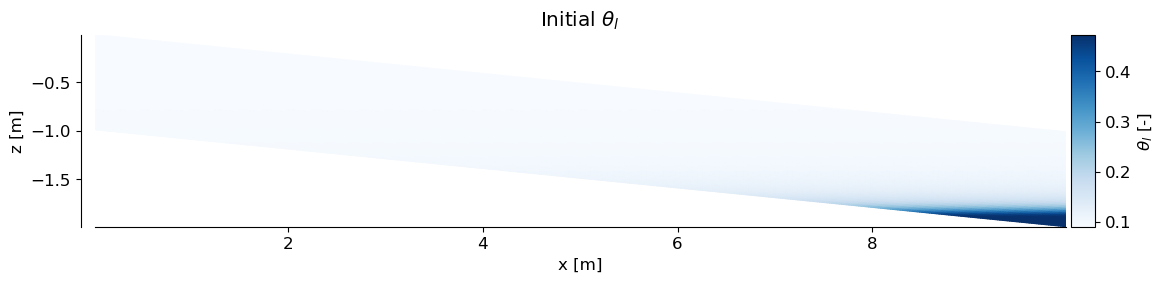

In [ ]:
theta_l, theta_i=petro.water_content_caps(h_c,T_init,geom.R,geom.n_caps,geom.theta_steps,alpha,N,Theta_r,Theta_s)
theta_l_vG = petro.watercontent(h_c, alpha, N, Theta_s, Theta_r)
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l+Theta_r, colormap="Blues", title=r"Initial $\theta_l$", colorbar_label=r'$\theta_l$ [-]')
# plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l+Theta_r-theta_l_vG, colormap="grey", title=r"Initial $\theta_i$", colorbar_label=r'$\theta_i$ [-]')

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $K_u$'}, xlabel='x [m]', ylabel='z [m]'>)

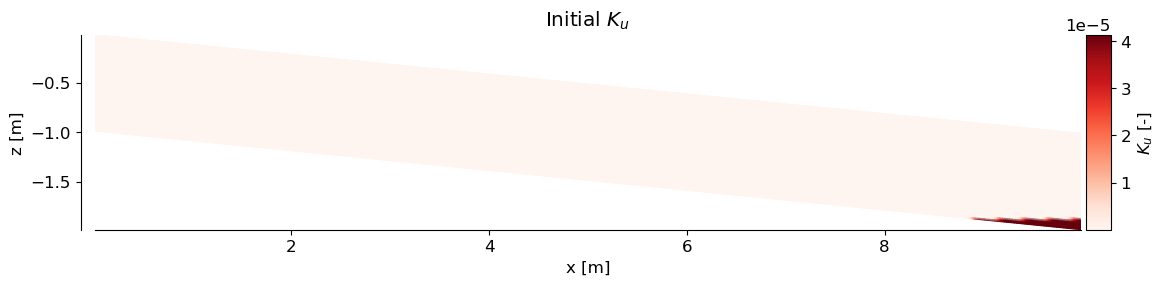

In [ ]:
Ku, k_rel, K_s_bundle = petro.K_u_caps(h_c,T_init,geom.R,geom.n_caps,geom.theta_steps,alpha,N,Theta_r,Theta_s)
plotting_utils.plot_cellValues(geom.X,geom.Z, k_rel*Ksat, colormap="Reds", title=r"Initial $K_u$", colorbar_label=r'$K_u$ [-]')
# Se = petro.effsat(h_c, alpha, N)
# krel = petro.relperm(Se,N)
# plotting_utils.plot_cellValues(geom.X,geom.Z, (k_rel-krel)*Ksat, colormap="RdBu", title=r"Initial $k_{rel}$", colorbar_label=r'$k_rel$ [-]')

### Set Initial Condition

In [ ]:
geom.set_initial_conditions(htot, h_c, theta_l, T_init)

===============   Setting initial conditions   =============== 
DONE: set initial conditions.


### Thermal Parameters

In [ ]:
rho_l = 1000
rho_i = 917
rho_s = 2650
rho_a = 1200

c_s = 800/1e9
c_l = 4180/1e9
c_i = 2100/1e9
c_a = 1000/1e9

H_f = 3.34e5/1e9

geom.set_thermal_params(rho_l, rho_i, rho_s, rho_a, c_l, c_i, c_s, c_a, H_f)

### Numerical Parameters

In [ ]:
restol=5e-4;      # accepted residual in Newton step
maxiter=10;      # maxmum number of iterations in Newton step
miniter=5;        # minimum number of iterations in Newton step

geom.set_solver_params(restol, maxiter, miniter,solver='newton')

===============   Setting Newton-Raphson parameters   =============== 
Restol: 0.0005
Max Iterations: 10
Min Iterations: 5
DONE: set Newton-Raphson parameters.


In [ ]:
[h_total, h_c_total, theta_l_total,theta_i_total, T_total, qx_array,qz_array,qx_centered_array,qz_centered_array, time_array, iter_total, normres_total] = geom.simulate_cap_bundle()

Starting simulation ...
Time 0.00 d, dt=6.00e+01, NR iterations=7, ||res||_inf=2.197e-04
Time 0.00 d, dt=6.00e+01, NR iterations=5, ||res||_inf=5.335e-06
Time 0.00 d, dt=6.00e+01, NR iterations=4, ||res||_inf=8.577e-06
Time 0.00 d, dt=1.20e+02, NR iterations=4, ||res||_inf=1.337e-04
Time 0.00 d, dt=1.20e+02, NR iterations=3, ||res||_inf=4.836e-04
Time 0.01 d, dt=1.20e+02, NR iterations=3, ||res||_inf=1.411e-04
Time 0.01 d, dt=2.40e+02, NR iterations=3, ||res||_inf=4.080e-04
Time 0.01 d, dt=2.40e+02, NR iterations=3, ||res||_inf=2.321e-04
Time 0.01 d, dt=2.40e+02, NR iterations=2, ||res||_inf=4.830e-04
Time 0.02 d, dt=4.80e+02, NR iterations=3, ||res||_inf=1.275e-04
Time 0.03 d, dt=4.80e+02, NR iterations=3, ||res||_inf=2.029e-05
Time 0.03 d, dt=4.80e+02, NR iterations=2, ||res||_inf=4.508e-04
Time 0.04 d, dt=9.60e+02, NR iterations=3, ||res||_inf=2.841e-05
Time 0.05 d, dt=9.60e+02, NR iterations=3, ||res||_inf=1.773e-05
Time 0.06 d, dt=9.60e+02, NR iterations=2, ||res||_inf=4.712e-04
T

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Final $\\theta_l$'}, xlabel='x [m]', ylabel='z [m]'>)

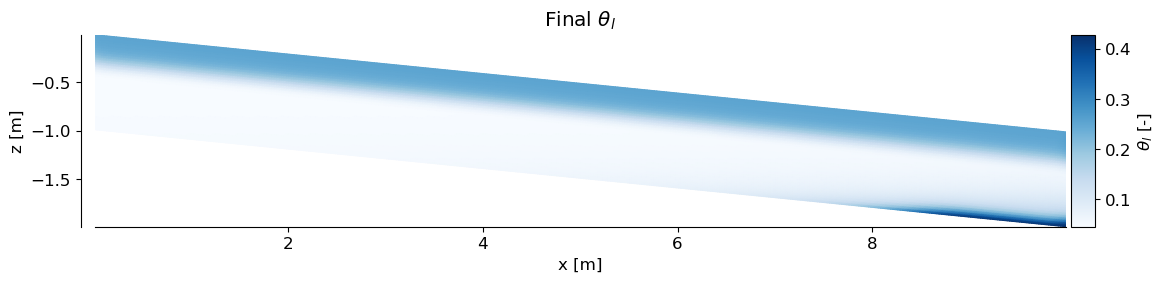

In [ ]:
index = -1
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l_total[index], colormap="Blues", title=r"Final $\theta_l$", colorbar_label=r'$\theta_l$ [-]')